# Figure 4 Supplement 1: Reward rate vs. bound (predefined-bound task)

The analyses of Figure 4 for the predefined-bound (PD) task, low-SNR blocks 1–3. In PD the subject
sets the bound before each trial, so the bound is known exactly (`get_data_table`'s
`task_type='PD'`: no NDT, no bias correction, DT = RT).

- **A–C** (one panel per block): each subject's mean bound (x; error bars = SD of the bound set
  across trials) against their reward rate (y). The benchmark has no aborted trials (participants can
  abort a trial with a key press, which costs its steps but earns no coins). Red: the reward rate of a fixed bound (median, with
  the 5th–95th percentile of 1000 simulated subjects per bound, PD's 800-step blocks; as in the
  task, the trial ends on the step that reaches the bound); dotted red
  box: near-optimal bounds (median reward rate ≥ 95% of its maximum; only its width carries information). Large black circle: the
  participants' median bound and reward rate.
- **D–F** (one panel per block): within-block adaptation. Mean ± SEM across subjects of the
  smoothed, z-scored |bound| over the first 40 trials; gray band: permutation null (max-statistic
  corrected, 95%). Inset: τ of the exponential settle for subjects with a good fit (box plot from 5
  fits up; points only below that), labeled `n = <shown fits>/<subjects with data>`
  (fits at the τ limit are left out; their counts are printed for the caption).


In [1]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import scipy.stats

from pigeon.adaptation import get_adaptation_tau_fits, get_sequential_bound_stats, group_null_band
from pigeon.data import get_data_table
from pigeon.path_defaults import FIGURES_DIR
from pigeon.plotting import (CM, FS_INSET, CONDITION_LABELS, DATA_COLOR, MEDIAN_MARKER, OPTIMAL_COLOR, SUBJECT_MARKER,
                             SUBJECT_SCATTER,
                             add_panel_label, format_p, use_figure_style)
from pigeon.simulation import BLOCK_DEFAULTS_PD, get_simulated_data_table

## Data

- **Bound:** mean and SD of |bound| per subject and block over trials with trial_number ≥ 10 on
  which the pigeon reached the set bound. The standard filter for measured bounds (DT ≥ 2, no wall
  hit, RT cutoff) is not applied: the bound here is set by the participant, and a wall hit in PD is
  the bound-crossing step overshooting to the screen edge. Trials with no choice have no bound and
  are left out (counts printed): the participant aborted the trial with a key press, or the block's
  step budget ran out mid-trial.
- **Reward rate:** the coins at the end of the block (the last recorded `coin_count`) / 800 steps
  (PD's step budget, `BLOCK_DEFAULTS_PD`). The task occasionally logged a block-end bonus message in
  place of the last trial's coin count, so that trial's coins can be missing (at most one trial per
  block).

In [2]:
BLOCKS = [1, 2, 3]   # raw PD blocks 1-3: low SNR; no penalty, coin penalty, step penalty
STEPS_PER_BLOCK_PD = BLOCK_DEFAULTS_PD[1]['steps_per_block']

data_table_pd = get_data_table(task_type='PD', combine_snr=False)
subjects = np.sort(data_table_pd['subject_index'].dropna().unique())

# Mean and SD of |bound| per subject x block, over trials with trial_number >= 10 that reached the bound
l_blocks = data_table_pd['block_index'].isin(BLOCKS) & (data_table_pd['trial_number'] >= 10)
l_no_choice = l_blocks & data_table_pd['choice'].isna()
print(f'{int(l_no_choice.sum())} of {int(l_blocks.sum())} trials ({100 * l_no_choice.sum() / l_blocks.sum():.1f}%) '
      'with no choice (aborted or out of steps), left out; '
      f'{int((l_blocks & data_table_pd.wall_hit).sum())} wall-hit and {int((l_blocks & (data_table_pd.DT < 2)).sum())} '
      'one-step trials kept')
g = data_table_pd[l_blocks & ~l_no_choice].groupby(['subject_index', 'block_index'])['abs_bound']
bound_mean = g.mean().unstack().reindex(index=subjects, columns=BLOCKS).to_numpy()
bound_sd = g.std().unstack().reindex(index=subjects, columns=BLOCKS).to_numpy()

# Reward rate: coins at the end of each block (coin_count is a running total) per step.
rr = (data_table_pd[data_table_pd['block_index'].isin(BLOCKS)].sort_values('trial_number')
      .groupby(['subject_index', 'block_index'])['coin_count'].last()
      .unstack().reindex(index=subjects, columns=BLOCKS).to_numpy() / STEPS_PER_BLOCK_PD)

# Fixed-bound reward-rate simulations for the figure, at the low SNR of blocks 1-3.
GENERATIVE_STD  = 0.15                                                         # per-step noise SD (PD task)
GENERATIVE_MEAN = float(np.nanmin(np.abs(data_table_pd['snr']))) * GENERATIVE_STD
SIM_BOUNDS      = np.arange(0.01, 0.72, 0.02)   # bound sweep, to the panel edge
NUM_SIM_SUBJ    = 1000                          # simulated subjects per bound (as in Figure04)
print(f'GENERATIVE_MEAN={GENERATIVE_MEAN:.4f} (SNR={GENERATIVE_MEAN / GENERATIVE_STD:.3f})')


1091 of 14232 trials (7.7%) with no choice (aborted or out of steps), left out; 593 wall-hit and 175 one-step trials kept
GENERATIVE_MEAN=0.0500 (SNR=0.333)


## Statistics per block

Median [IQR] of the mean bound across subjects, and the Spearman correlation between mean bound
and reward rate (subjects with both values).

Text only (no panel): for consecutive blocks, each subject's change in mean bound (median [IQR],
Wilcoxon signed-rank test) and the Spearman correlation between the two blocks' mean bounds; and per
block, the lag-1 autocorrelation of the set bound (Pearson r between consecutive trials' |bound|,
same trials as A–C), median [IQR] across subjects, Wilcoxon signed-rank test against 0.

In [3]:
for bi, block in enumerate(BLOCKS):
    valid = np.isfinite(bound_mean[:, bi]) & np.isfinite(rr[:, bi])
    q25, med, q75 = np.percentile(bound_mean[valid, bi], [25, 50, 75])
    r, p = scipy.stats.spearmanr(bound_mean[valid, bi], rr[valid, bi])
    print(f'Block {block}: mean bound {med:.3f} [{q25:.3f}, {q75:.3f}]; bound vs. reward rate '
          f'Spearman r={r:.3f}, {format_p(p)} (n={valid.sum()})')


Block 1: mean bound 0.253 [0.146, 0.372]; bound vs. reward rate Spearman r=-0.636, p<0.001 (n=59)
Block 2: mean bound 0.388 [0.288, 0.461]; bound vs. reward rate Spearman r=0.494, p<0.001 (n=59)
Block 3: mean bound 0.271 [0.150, 0.367]; bound vs. reward rate Spearman r=0.017, p=0.905 (n=54)


In [4]:
# Block-to-block change in each subject's mean bound (later minus earlier block) and how stable the subjects'
# ordering is across the two blocks (subjects with both blocks), as in Figure 4.
for bi in range(len(BLOCKS) - 1):
    valid = np.isfinite(bound_mean[:, bi]) & np.isfinite(bound_mean[:, bi + 1])
    diff = bound_mean[valid, bi + 1] - bound_mean[valid, bi]
    q25, med, q75 = np.percentile(diff, [25, 50, 75])
    p_w = scipy.stats.wilcoxon(diff).pvalue
    r, p_r = scipy.stats.spearmanr(bound_mean[valid, bi], bound_mean[valid, bi + 1])
    print(f'Block {BLOCKS[bi]} -> {BLOCKS[bi + 1]}: mean-bound change {med:.3f} [{q25:.3f}, {q75:.3f}], '
          f'Wilcoxon {format_p(p_w)}; bound vs. bound Spearman r={r:.3f}, {format_p(p_r)} (n={valid.sum()})')

# Lag-1 autocorrelation of the set bound: Pearson r between consecutive trials' |bound| per subject x block,
# over the same trials as A-C (sequences with fewer than MIN_SEQ_TRIALS trials get no value; counts printed).
MIN_SEQ_TRIALS = 20
seq = get_sequential_bound_stats(data_table_pd[l_blocks & ~l_no_choice], min_trials=MIN_SEQ_TRIALS)
for block in BLOCKS:
    s = seq.xs(block, level='block_index')
    r1 = s['lag1_r'].dropna()
    q25, med, q75 = np.percentile(r1, [25, 50, 75])
    print(f'Block {block}: lag-1 autocorrelation of |bound| {med:.3f} [{q25:.3f}, {q75:.3f}], '
          f'Wilcoxon vs. 0 {format_p(scipy.stats.wilcoxon(r1).pvalue)} (n={len(r1)}; '
          f'{len(s) - len(r1)} subject(s) with < {MIN_SEQ_TRIALS} trials left out)')

Block 1 -> 2: mean-bound change 0.072 [-0.012, 0.193], Wilcoxon p<0.001; bound vs. bound Spearman r=0.282, p=0.032 (n=58)
Block 2 -> 3: mean-bound change -0.097 [-0.205, -0.002], Wilcoxon p<0.001; bound vs. bound Spearman r=0.384, p=0.004 (n=54)
Block 1: lag-1 autocorrelation of |bound| 0.898 [0.677, 0.959], Wilcoxon vs. 0 p<0.001 (n=52; 7 subject(s) with < 20 trials left out)
Block 2: lag-1 autocorrelation of |bound| 0.908 [0.866, 0.954], Wilcoxon vs. 0 p<0.001 (n=51; 8 subject(s) with < 20 trials left out)
Block 3: lag-1 autocorrelation of |bound| 0.893 [0.832, 0.961], Wilcoxon vs. 0 p<0.001 (n=41; 13 subject(s) with < 20 trials left out)


## Within-block adaptation (D–F)

As in Figure 4, but on |bound| itself (the bound is set, not measured, so there is no measurement
model to remove): `pigeon.adaptation.get_adaptation_tau_fits` z-scores |bound| per subject × block,
smooths it with a ±3-trial window over the first 40 trials (every trial that reached the bound, no
trial-number floor; `apply_quality_filter=False`, as for the bound in A–C), and tests it against 1000 trial-order permutations; the gray band is the
max-statistic threshold of the group-mean null curves. τ (`A·exp(−t/τ) + C`) is fit for eligible
subjects: in block 1, those whose curve differs from their null; in blocks 2 and 3, those whose
steady-state |bound| differs from the previous block (Mann–Whitney U). Fits at the τ limit (40
trials) are censored and left out.


In [5]:
MAX_TRIAL = 40   # trials from the start of the block in the curves (and the tau limit)

tau_fits = get_adaptation_tau_fits(data_table_pd, blocks=BLOCKS, max_trial=MAX_TRIAL, apply_quality_filter=False)
trial_nums, curves = tau_fits['trial_nums'], tau_fits['real_curves']
taus, censored = tau_fits['taus'], tau_fits['censored']
n_valid = np.sum(np.isfinite(curves), axis=0)
curve_mean = np.nanmean(curves, axis=0)
curve_sem = np.nanstd(curves, axis=0) / np.sqrt(np.maximum(n_valid, 1))
curve_sem[n_valid < 2] = np.nan
null_thresh = group_null_band(tau_fits['perm_curves'])

for bi, block in enumerate(BLOCKS):
    n_total = np.sum(np.any(np.isfinite(curves[:, :, bi]), axis=1))
    max_abs = np.nanmax(np.abs(curve_mean[:, bi]))
    criterion = ('within-block adaptation' if bi == 0
                 else f'change vs. block {BLOCKS[bi - 1]} (Mann-Whitney U)')
    vt = taus[:, bi][np.isfinite(taus[:, bi]) & ~censored[:, bi]]
    print(f'Block {block}: {tau_fits["sig_within"][:, bi].sum()}/{n_total} subjects with within-block adaptation; '
          f'group curve max |z| {max_abs:.3f} vs. null {null_thresh[bi]:.3f}')
    print(f'  tau-fit eligible ({criterion}): {tau_fits["sig_tau"][:, bi].sum()}/{n_total}; '
          f'{censored[:, bi].sum()} censored at {MAX_TRIAL}; '
          + (f'tau median {np.median(vt):.1f} [{np.percentile(vt, 25):.1f}, {np.percentile(vt, 75):.1f}], '
             f'n={len(vt)}' if len(vt) else 'no uncensored fits'))


Block 1: 54/60 subjects with within-block adaptation; group curve max |z| 0.783 vs. null 0.159
  tau-fit eligible (within-block adaptation): 54/60; 22 censored at 40; tau median 4.8 [3.2, 10.6], n=32
Block 2: 57/60 subjects with within-block adaptation; group curve max |z| 1.567 vs. null 0.162
  tau-fit eligible (change vs. block 1 (Mann-Whitney U)): 48/60; 13 censored at 40; tau median 11.8 [7.3, 23.0], n=35
Block 3: 45/54 subjects with within-block adaptation; group curve max |z| 0.712 vs. null 0.172
  tau-fit eligible (change vs. block 2 (Mann-Whitney U)): 42/54; 21 censored at 40; tau median 10.0 [3.6, 19.0], n=21


## Figure

17.6 cm wide, 2 rows × 3 columns; saves `Figure04_S01.pdf` (+ `.png`) to `FIGURES_DIR`.


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Block 1: near-optimal bounds (>=95% of max median RR) 0.01-0.03
Block 2: near-optimal bounds (>=95% of max median RR) 0.43-0.61
Block 3: near-optimal bounds (>=95% of max median RR) 0.25-0.41


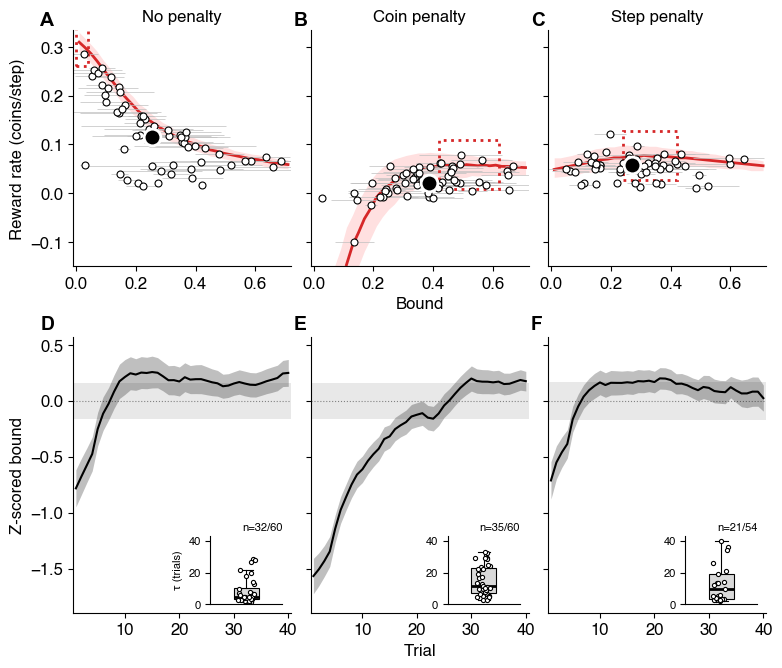

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure04_S01.pdf (+ .png)


In [6]:
WID = 17.6
HTS = [6.0, 7.0]
PSH = 1.8
PSW = 0.5
use_figure_style()

fig_h       = sum(HTS) + PSH
panel_w     = (WID - 2 * PSW) / 3
hspace_frac = PSH / np.mean(HTS)
wspace_frac = PSW / panel_w

fig_comb = plt.figure(figsize=(WID * CM, fig_h * CM))
gs_comb  = gridspec.GridSpec(2, 3, figure=fig_comb,
                              height_ratios=HTS,
                              hspace=hspace_frac, wspace=wspace_frac,
                              left=0, right=1, bottom=0, top=1)
axs_top = [fig_comb.add_subplot(gs_comb[0, c]) for c in range(3)]
axs_bot = [fig_comb.add_subplot(gs_comb[1, c]) for c in range(3)]

gr_c = (0.75, 0.75, 0.75)
rp_c = (1.0,  0.88, 0.88)   # light red: spread of the simulated (optimal-benchmark) reward rates

# ── Pre-compute simulation ribbons for all blocks (single RNG pass) ───────────
# Done up-front so we can determine axis limits before drawing anything.
rng_comb = np.random.default_rng(0)
sbd_all = []
for bi, block in enumerate(BLOCKS):
    sbd = np.full((len(SIM_BOUNDS), 3), np.nan)
    for ss, bnd in enumerate(SIM_BOUNDS):
        sim_table = get_simulated_data_table(
            specs={'num_subjects': NUM_SIM_SUBJ, 'blocks': block},
            generative_mean=GENERATIVE_MEAN,
            bound_mean=bnd,
            ndt_min=0, ndt_max=0,   # PD: the trial ends on the step that reaches the bound
            rng=rng_comb,
            block_defaults=BLOCK_DEFAULTS_PD,
        )
        sim_coins = sim_table.groupby('subject_index')['coin_count'].last().to_numpy()
        sbd[ss] = np.percentile(sim_coins, [5, 50, 95]) / STEPS_PER_BLOCK_PD
    sbd_all.append(sbd)

# Axis limits (x extends left if the RR peak is at the smallest bound); y from just below the
# lowest participant reward rate, as in Figure04
all_opt_idx = [int(np.nanargmax(sbd[:, 1])) for sbd in sbd_all]
all_opt_x   = [float(SIM_BOUNDS[i]) for i in all_opt_idx]
all_opt_y   = [float(sbd_all[bi][all_opt_idx[bi], 1]) for bi in range(3)]
x_left      = min(0.0, min(all_opt_x) - 0.02)
y_top       = max(max(all_opt_y) * 1.08, 0.32)
TOP_XLIM    = (x_left, 0.72)
NEAR_OPT_BOX_HEIGHT = 0.1   # coins/step, as in Figure 4; the box's height carries no information
_rr_all     = rr
Y_FLOOR     = float(np.floor((np.nanmin(_rr_all) - 0.02) * 20) / 20)   # round down to 0.05
TOP_YLIM    = (Y_FLOOR, y_top)

# ── Top row: RR vs. bound ─────────────────────────────────────────────────────
# Ideal RR curve is red, matching the ideal-observer curve in Figure02c, as is the
# near-optimal box. The empirical data — participant scatter and the median (large circle) — are black.
for bi, block in enumerate(BLOCKS):
    ax  = axs_top[bi]
    sbd = sbd_all[bi]

    ax.fill_between(SIM_BOUNDS, np.maximum(sbd[:, 0], Y_FLOOR), np.maximum(sbd[:, 2], Y_FLOOR),
                    color=rp_c, linewidth=0)
    ax.plot(SIM_BOUNDS, np.where(sbd[:, 1] >= Y_FLOOR, sbd[:, 1], np.nan), '-', color=OPTIMAL_COLOR, linewidth=2)

    # Near-optimal bounds (median RR >= 95% of its maximum) as a red box, outlined like Figure 5's
    # near-optimal contour; no single optimum is marked, since the curves are nearly flat near their peak.
    _near = SIM_BOUNDS[sbd[:, 1] >= 0.95 * np.nanmax(sbd[:, 1])]
    # Dotted, to set it apart from the solid red curve; fixed height centered on the curve's maximum
    # (only the width carries information).
    _x0, _x1 = max(_near.min() - 0.01, TOP_XLIM[0]), _near.max() + 0.01
    _y0 = np.nanmax(sbd[:, 1]) - NEAR_OPT_BOX_HEIGHT / 2
    ax.add_patch(plt.Rectangle((_x0, _y0), _x1 - _x0, NEAR_OPT_BOX_HEIGHT, facecolor='none', edgecolor=OPTIMAL_COLOR,
                               lw=2, ls=':', zorder=3))
    print(f'Block {block}: near-optimal bounds (>=95% of max median RR) {_near.min():.2f}-{_near.max():.2f}')

    # Data scatter: one point per subject, horizontal error bars = ±1 SD bound
    mean_b   = bound_mean[:, bi]
    std_b    = bound_sd[:, bi]
    rr_b     = rr[:, bi]
    valid_bi = np.isfinite(mean_b) & np.isfinite(rr_b)

    ax.errorbar(mean_b[valid_bi], rr_b[valid_bi],
                xerr=std_b[valid_bi], fmt='none',
                ecolor=gr_c, elinewidth=0.5, capsize=0)
    ax.plot(mean_b[valid_bi], rr_b[valid_bi], **SUBJECT_MARKER, zorder=4)

    # Participants' median bound and reward rate
    ax.plot(np.nanmedian(mean_b[valid_bi]), np.nanmedian(rr_b[valid_bi]), **MEDIAN_MARKER, zorder=5)

    ax.set_xlim(*TOP_XLIM)
    ax.set_ylim(*TOP_YLIM)
    if x_left < 0:
        ax.set_xticks([0, 0.2, 0.4, 0.6])   # hide the negative-margin tick
    ax.set_title(CONDITION_LABELS[block])
    if bi == 1:
        ax.set_xlabel('Bound')
    if bi == 0:
        ax.set_ylabel('Reward rate (coins/step)')
    else:
        ax.tick_params(axis='y', labelleft=False)
    for sp in ['top', 'right']:
        ax.spines[sp].set_visible(False)

# ── Bottom row: within-block learning curves with τ insets ───────────────────
# Curve + ribbon are black (empirical data), consistent with the top row's
# black data crosshairs. The permutation null band is a light gray, chosen to
# stay visually distinct from the black curve/ribbon (which render as a
# mid-gray at alpha=0.25) rather than blending into it.
_NULL_COLOR  = (0.85, 0.85, 0.85)
_CURVE_COLOR = 'k'

_top_lo  = min(np.nanmin(curve_mean - curve_sem), -np.max(null_thresh))
_top_hi  = max(np.nanmax(curve_mean + curve_sem),  np.max(null_thresh))
_top_pad = 0.08 * (_top_hi - _top_lo)
_CURVE_YLIM = (_top_lo - _top_pad, _top_hi + _top_pad)

_rng_jit = np.random.default_rng(42)

for bi, block in enumerate(BLOCKS):
    ax = axs_bot[bi]
    mn  = curve_mean[:, bi]
    sem = curve_sem[:, bi]
    ok  = np.isfinite(mn) & np.isfinite(sem)
    thr = null_thresh[bi]

    ax.axhline(0, color='k', linestyle=':', linewidth=0.8, zorder=0)
    ax.axhspan(-thr, thr, color=_NULL_COLOR, alpha=0.6, linewidth=0, zorder=0)
    ax.fill_between(trial_nums[ok], mn[ok] - sem[ok], mn[ok] + sem[ok],
                    alpha=0.25, color=_CURVE_COLOR, linewidth=0)
    ax.plot(trial_nums[ok], mn[ok], '-', color=_CURVE_COLOR, linewidth=1.5)

    ax.set_xlim(0.5, MAX_TRIAL + 0.5)
    ax.set_ylim(*_CURVE_YLIM)
    if bi == 0:
        ax.set_ylabel('Z-scored bound')
    else:
        ax.tick_params(axis='y', labelleft=False)
    if bi == 1:
        ax.set_xlabel('Trial')
    for sp in ['top', 'right']:
        ax.spines[sp].set_visible(False)

    # ── τ inset (lower-right corner of the learning-curve panel) ──────────────
    ax_ins = ax.inset_axes([0.63, 0.03, 0.33, 0.25])

    is_cens = censored[:, bi]
    vt      = taus[:, bi][np.isfinite(taus[:, bi]) & ~is_cens]
    n_total = int(np.sum(np.any(np.isfinite(curves[:, :, bi]), axis=1)))

    if len(vt) >= 5:
        ax_ins.boxplot(vt, positions=[1], widths=0.35,
                       patch_artist=True,
                       medianprops=dict(color='k', linewidth=2),
                       boxprops=dict(facecolor=(0.85, 0.85, 0.85), linewidth=0.8),
                       whiskerprops=dict(linewidth=0.8),
                       capprops=dict(linewidth=0.8),
                       flierprops=dict(marker='none'))
    if len(vt):
        jit = _rng_jit.uniform(-0.12, 0.12, len(vt))
        ax_ins.scatter(np.ones(len(vt)) + jit, vt, **{**SUBJECT_SCATTER, 's': 3**2}, zorder=4)   # smaller in the inset
    else:
        ax_ins.text(1, MAX_TRIAL / 2, 'no fits', ha='center', va='center', fontsize=FS_INSET)

    # n label above the inset: shown fits (successful, below the τ limit) over all subjects with data in this
    # block; the rest (not eligible, at the limit) are counted in the printout above, for the caption.
    ax_ins.text(1.0, 1.05, f'n={len(vt)}/{n_total}',
                transform=ax_ins.transAxes, ha='right', va='bottom', fontsize=FS_INSET)

    ax_ins.set_xlim(0.5, 1.5)
    ax_ins.set_ylim(0, MAX_TRIAL * 1.08)
    ax_ins.set_xticks([])
    if bi == 0:
        ax_ins.set_ylabel('τ (trials)', fontsize=FS_INSET)
    ax_ins.tick_params(labelsize=FS_INSET)
    for sp in ['top', 'right']:
        ax_ins.spines[sp].set_visible(False)

for bi in range(3):
    dx = -0.15 if bi == 0 else -0.08   # columns 2-3 have no y tick labels: keep the letter close to its own axes
    add_panel_label(axs_top[bi], chr(65 + bi), dx=dx)
    add_panel_label(axs_bot[bi], chr(68 + bi), dx=dx)

out_comb = FIGURES_DIR / 'Figure04_S01.pdf'
fig_comb.savefig(out_comb, dpi=300, bbox_inches='tight')
fig_comb.savefig(out_comb.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out_comb} (+ .png)')

